# 06 · Decay, drift and late labels

A fraud model starts decaying the day it ships: fraudsters adapt, and the labels that would show
it arrive weeks later, when chargebacks come in. Three questions:

1. How fast does a gradient-boosting model (the phase-3 recipe, without the `V` columns) decay over the later
   months, and does refitting it help?
2. Which inputs drift, and does the score's own distribution move (a signal available at once)?
3. With chargebacks arriving weeks late, what can monitoring see in time, and what fills the gap?

In [1]:
import sys
from pathlib import Path


def _project_root() -> Path:
    here = Path.cwd().resolve()
    for p in (here, *here.parents):
        if (p / "src" / "fraudrisk" / "__init__.py").exists():
            return p
    raise FileNotFoundError("run from inside the project folder")


sys.path.insert(0, str(_project_root() / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fraudrisk import config, data, features, model, monitoring
from fraudrisk.records import show_verdict, write_metrics

SOURCE = data.source()
# several refits here are comparisons, not the production model: a faster learning rate keeps them affordable
GBM_PARAMS = {"learning_rate": 0.1} if SOURCE == "real" else {"learning_rate": 0.2, "num_leaves": 15}
GBM_ROUNDS = 400 if SOURCE == "real" else 150
WIDTH = 15                                     # days per monitoring window
con = data.connect()
features.build(con)
F = features.frame(con)
raw = con.sql(f"SELECT {', '.join(model.raw_columns(with_v=False))} FROM tx").df()
D = model.design(F, raw, with_v=False)
del raw
y, amount, day, split = D.y, D.amount, D.day, D.split
win = monitoring.windows(day, data.TRAIN_END, WIDTH)
print(SOURCE, D.X.shape, f"{win.max() + 1} windows of {WIDTH} days after day {data.TRAIN_END}")

real (590540, 95) 4 windows of 15 days after day 120


## 1. Decay, and refitting

**Frozen**: fitted once on days 0–119 (validation months only for early stopping). **Refitted**:
before each window, refitted on every transaction whose label would have arrived by then, i.e.
older than the median chargeback delay, so the refit does not use labels it could not have had.

In [2]:
def fit_on(mask_train, mask_stop):
    sub_split = np.where(mask_train, "train", np.where(mask_stop, "valid", "other"))
    d = model.Design(X=D.X, y=y, split=sub_split, amount=amount, day=day, transaction_id=D.transaction_id)
    return model.fit_lightgbm(d, GBM_PARAMS, GBM_ROUNDS)


frozen = fit_on(split == "train", split == "valid")
s_frozen = frozen.predict(D.X, num_iteration=frozen.best_iteration)
delay = config.LABEL_DELAY_MEDIAN_DAYS
rows = []
s_refit = np.full(len(y), np.nan)
for w in range(win.max() + 1):
    start = data.TRAIN_END + w * WIDTH
    known = day < start - delay                       # labels available at the window's start (by the median delay)
    stop = (day >= start - delay - WIDTH) & known     # the most recent known window, for early stopping
    g = fit_on(known & ~stop, stop)
    in_w = win == w
    s_refit[in_w] = g.predict(D.X[in_w], num_iteration=g.best_iteration)
    for name, s in (("frozen", s_frozen), ("refitted", s_refit)):
        e = model.evaluate(s[in_w], y[in_w], amount[in_w])
        rows.append({"window": w, "first_day": start, "model": name, "payments": int(in_w.sum()),
                     "frauds": int(y[in_w].sum()), "pr_auc": e["pr_auc"], "recall_at_capacity": e["recall_at_capacity"]})
decay = pd.DataFrame(rows)
decay.pivot(index="first_day", columns="model", values=["pr_auc", "recall_at_capacity"]).round(3)

pr_auc          recall_at_capacity         
model     frozen refitted             frozen refitted
first_day                                            
120        0.665    0.522              0.390    0.353
135        0.481    0.422              0.325    0.290
150        0.508    0.496              0.350    0.345
165        0.492    0.492              0.279    0.279

## 2. Drift

PSI of each input between the training months and the test months, and of the frozen model's
score in each window against its training distribution. The score's PSI needs no labels, so it is
available the same day.

In [3]:
tr, te = split == "train", split == "test"
num = [c for c in D.X.columns if str(D.X[c].dtype) != "category"]
feature_psi = pd.Series({c: monitoring.psi(D.X.loc[tr, c], D.X.loc[te, c]) for c in num}).sort_values(ascending=False)
score_psi = pd.Series({int(data.TRAIN_END + w * WIDTH): monitoring.psi(s_frozen[tr], s_frozen[win == w])
                       for w in range(win.max() + 1)}, name="score PSI")
print(f"inputs with PSI > 0.25: {int((feature_psi > 0.25).sum())} of {len(feature_psi)}")
feature_psi.head(10).round(3)

inputs with PSI > 0.25: 6 of 69


D1_date             1.812
D10_date            1.301
D15_date            0.990
D4_date             0.990
D2_date             0.510
D11                 0.334
card1_freq          0.132
cust_prior_tx       0.118
hours_since_prev    0.098
D15                 0.097
dtype: float64

In [4]:
score_psi.round(3)

120    0.002
135    0.007
150    0.011
165    0.030
Name: score PSI, dtype: float64

## 3. What monitoring sees when labels are late

Chargeback delays are simulated (exponential, median 30 days: a scenario assumption). For each
window, the share of its fraud labels known 7, 30 and 60 days after the window closes, and the
recall at capacity a dashboard would show then (computed on the labels known so far) against the
final value. The review queue is different: reviewers' verdicts arrive the same day, so the
queue's hit rate (precision) is known at once.

In [5]:
arrive = monitoring.label_arrival(len(y), delay)
lag_rows = []
for w in range(win.max() + 1):
    in_w = win == w
    end = int(day[in_w].max()) + 1
    s = s_frozen[in_w]
    k = max(1, int(round(config.REVIEW_CAPACITY * in_w.sum())))
    flagged = np.zeros(in_w.sum(), bool)
    flagged[np.argsort(-s, kind="stable")[:k]] = True
    yw = y[in_w]
    for lag in (7, 30, 60, None):
        if lag is None:
            known_label = np.ones(in_w.sum(), bool)
        else:
            known_label = (day[in_w] + arrive[in_w]) <= end + lag
        y_known = yw * known_label
        lag_rows.append({"window_first_day": data.TRAIN_END + w * WIDTH, "days after window": "final" if lag is None else lag,
                         "share_of_fraud_labels_known": float(y_known.sum() / max(yw.sum(), 1)),
                         "measured_recall": float(y_known[flagged].sum() / max(y_known.sum(), 1)),
                         "review_queue_hit_rate": float(yw[flagged].mean())})
lags = pd.DataFrame(lag_rows)
lags.pivot(index="window_first_day", columns="days after window", values="share_of_fraud_labels_known").round(2)

days after window,7,30,60,final
window_first_day,,,,
120,0.27,0.58,0.79,1.0
135,0.27,0.57,0.78,1.0
150,0.29,0.58,0.78,1.0
165,0.32,0.60,0.80,1.0


In [6]:
lags.pivot(index="window_first_day", columns="days after window", values="measured_recall").round(3)

days after window,7,30,60,final
window_first_day,,,,
120,0.419,0.397,0.379,0.390
135,0.318,0.326,0.327,0.325
150,0.365,0.348,0.356,0.350
165,0.298,0.284,0.281,0.279


## 4. Figure

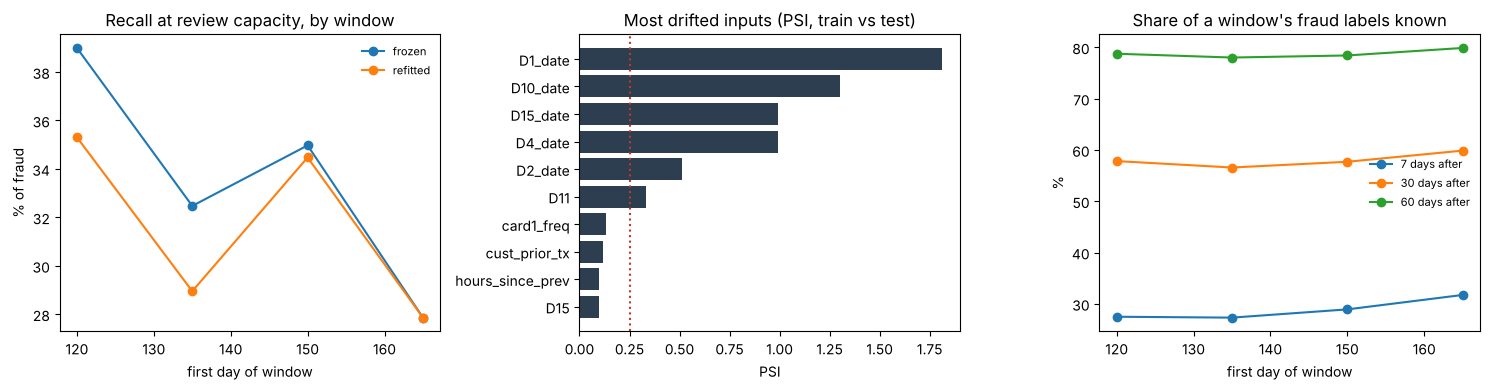

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ax = axes[0]
for name, g in decay.groupby("model"):
    ax.plot(g["first_day"], 100 * g["recall_at_capacity"], marker="o", label=name)
ax.set(title="Recall at review capacity, by window", xlabel="first day of window", ylabel="% of fraud")
ax.legend(fontsize=8, frameon=False)
ax = axes[1]
ax.barh(feature_psi.head(10).index[::-1], feature_psi.head(10).to_numpy()[::-1], color="#2c3e50")
ax.axvline(0.25, color="#c0392b", ls=":")
ax.set(title="Most drifted inputs (PSI, train vs test)", xlabel="PSI")
ax = axes[2]
known = lags[lags["days after window"] != "final"]
for lag, g in known.groupby("days after window"):
    ax.plot(g["window_first_day"], 100 * g["share_of_fraud_labels_known"], marker="o", label=f"{lag} days after")
ax.set(title="Share of a window's fraud labels known", xlabel="first day of window", ylabel="%")
ax.legend(fontsize=8, frameon=False)
fig.tight_layout()
data.savefig(fig, "06_monitoring", SOURCE)

## Record and verdict

In [8]:
piv = decay.pivot(index="first_day", columns="model", values="recall_at_capacity")
record = {
    "window_days": WIDTH, "label_delay_median_days": delay,
    "decay": decay.to_dict(orient="records"),
    "feature_psi_top10": {k: float(v) for k, v in feature_psi.head(10).items()},
    "features_psi_over_0_25": int((feature_psi > 0.25).sum()),
    "score_psi": {str(k): float(v) for k, v in score_psi.items()},
    "label_lag": lags.to_dict(orient="records"),
}
write_metrics("06_monitoring", record, SOURCE)

In [9]:
first, last = piv.iloc[0], piv.iloc[-1]
known30 = lags[lags["days after window"] == 30]["share_of_fraud_labels_known"].mean()
known7 = lags[lags["days after window"] == 7]["share_of_fraud_labels_known"].mean()
gain = (piv["refitted"] - piv["frozen"]).mean()
hit = lags[lags["days after window"] == "final"].set_index("window_first_day")["review_queue_hit_rate"]
m7 = lags[lags["days after window"] == 7].set_index("window_first_day")["measured_recall"]
mf = lags[lags["days after window"] == "final"].set_index("window_first_day")["measured_recall"]
err7 = float((m7 - mf).abs().mean())
record["review_queue_hit_rate"] = {str(k): float(v) for k, v in hit.items()}
record["measured_recall_error_at_7_days"] = err7
write_metrics("06_monitoring", record, SOURCE)
show_verdict(
    "Verdict: phase 6, decay and monitoring",
    [
        f"**Frozen, recall at capacity goes from {first['frozen']:.0%} in the first {WIDTH}-day window after training to "
        f"{last['frozen']:.0%} in the last.** Refitting before each window on only the labels a live system would have by "
        f"then changes it by {gain:+.1%} on average" + (": no better. " if gain < 0.01 else ". ") + "Part of the frozen model's early lead is hindsight, since it "
        "was trained on labels up to the day before the first window, which a live system would not yet have.",
        f"**{int((feature_psi > 0.25).sum())} of {len(feature_psi)} inputs drift strongly** (PSI > 0.25, train vs test); the "
        f"largest is `{feature_psi.index[0]}`" + (", which drifts by construction: the `_date` inputs are calendar dates"
                                                  if feature_psi.index[0].endswith("_date") else "") + ". "
        + (f"**The score's own distribution barely moved** (PSI {score_psi.min():.2f}–{score_psi.max():.2f}) while recall fell, "
         "so score drift alone would not have raised an alarm." if score_psi.max() < 0.1 else
         f"The score's own distribution moved (PSI up to {score_psi.max():.2f}), a label-free warning available the same day."),
        f"**Late labels slow the dashboard; the review queue does not wait.** With a {delay}-day median chargeback delay, "
        f"{known7:.0%} of a window's fraud labels are known a week after it closes and {known30:.0%} after a month. If delays "
        f"do not depend on the kind of fraud (an assumption), recall measured on early labels is noisy but not biased "
        f"(off by {err7:.1%} on average at one week). The reviewers' same-day verdicts are the fastest signal: the queue's "
        f"hit rate went from {hit.iloc[0]:.0%} in the first window to {hit.iloc[-1]:.0%} in the last.",
    ],
    "Packaging: README, decision memo, model card and the demo.",
)

### Verdict: phase 6, decay and monitoring

1. **Frozen, recall at capacity goes from 39% in the first 15-day window after training to 28% in the last.** Refitting before each window on only the labels a live system would have by then changes it by -1.9% on average: no better. Part of the frozen model's early lead is hindsight, since it was trained on labels up to the day before the first window, which a live system would not yet have.
2. **6 of 69 inputs drift strongly** (PSI > 0.25, train vs test); the largest is `D1_date`, which drifts by construction: the `_date` inputs are calendar dates. **The score's own distribution barely moved** (PSI 0.00–0.03) while recall fell, so score drift alone would not have raised an alarm.
3. **Late labels slow the dashboard; the review queue does not wait.** With a 30-day median chargeback delay, 29% of a window's fraud labels are known a week after it closes and 58% after a month. If delays do not depend on the kind of fraud (an assumption), recall measured on early labels is noisy but not biased (off by 1.7% on average at one week). The reviewers' same-day verdicts are the fastest signal: the queue's hit rate went from 92% in the first window to 72% in the last.

**Next:** Packaging: README, decision memo, model card and the demo.